# Email Automation Pipeline: EDA (M2)

**Is there signal in our email data?** This notebook checks the cleaned dataset
`data/emails_clean.csv` with four questions: column types, data quality,
distributions, and correlation (including a leakage check).

> **Insight: we found that 78.5% of the labelled business email belongs to `support`.**
> A model that always answers "support" is already 78.5% accurate, so overall accuracy
> will flatter any model. For the operations manager the hard (and valuable) part is
> routing the small departments (billing 15%, sales 3%, hr 2%) correctly, so M3 will be
> scored per department and with macro-F1, not only with accuracy.

**Baselines (the numbers the M3 model has to beat):**

| Task (target `y`) | Baseline | Accuracy | Macro-F1 |
|---|---|---|---|
| Department routing (`department`, 16,338 labelled emails) | Always predict `support` | **78.5%** | 0.18 |
| Spam filter (`spam`, 34,801 emails) | Always predict "not spam" | **88.5%** | 0.47 |

**Problem and audience:** start-ups and small companies spend expensive employee time
triaging a shared inbox. Our system filters spam, routes each email to the right
department and answers what it can, on local Ollama models.

**What we predict (`y`):** `spam` (binary 0/1) and `department` (categorical:
`billing`, `sales`, `support`, `hr`, `marketing`, `unclear`). The model's input is
only the email itself: `subject` and `body`.

**Data:** three Kaggle datasets combined by `scripts/build_dataset.py`
(details and cleaning decisions in `README.md`). All conclusions in this notebook are
also saved in `docs/data/eda-conclusions.md`.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

DATA_FILE = Path("data/emails_clean.csv")
DEPARTMENTS = ["billing", "sales", "support", "hr", "marketing", "unclear"]
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})
pd.set_option("display.max_colwidth", 80)

# keep_default_na=False: an empty subject is an empty string, not NaN.
emails = pd.read_csv(DATA_FILE, keep_default_na=False)
print(f"{len(emails):,} rows x {emails.shape[1]} columns")
emails.head()

34,801 rows x 8 columns


,id,source,from,subject,body,spam,department,reply
0,1,spam_dataset,customer0732@customer.test,Project Update,budget review - Series season change bar. Any environmental hold compare.,0,,
1,2,support_tickets,customer0418@customer.test,Account access,I'm having an issue with the Amazon Kindle. Please assist. Amazon Kindle Buy...,0,,
2,3,multilang_tickets,customer0705@customer.test,Device Compatibility Inquiry,"Dear Customer Support Team,\n\nI hope this message finds you well. I am reac...",0,support,Thank you for your inquiry regarding device compatibility. To provide precis...
3,4,multilang_tickets,customer0366@customer.test,Support Inquiry for Data Analytics Tools,"Hello Customer Support, I am reaching out to inquire about the data analytic...",0,support,"Hello, thank you for reaching out to our customer support team regarding the..."
4,5,multilang_tickets,customer0089@customer.test,Urgent Assistance Required for Digital Strategy Implementation,I am expressing urgent concern regarding the digital strategy deployed by ou...,0,support,We understand your concerns about the digital strategy challenges and are he...


## 1. Column types

Which columns are numeric, binary, categorical, identifiers, or free text?

In [3]:
KIND = {
    "id": "identifier (row number, carries no information)",
    "source": "categorical (3 values): which raw dataset the row came from",
    "from": "categorical / identifier: made-up sender from a pool of 1,000",
    "subject": "free text (can be empty)",
    "body": "free text",
    "spam": "binary 0/1 - TARGET 1",
    "department": "categorical (6 classes, empty = no label) - TARGET 2",
    "reply": "free text: agent's reference reply (IT tickets only)",
}
types = pd.DataFrame({
    "pandas dtype": emails.dtypes.astype(str),
    "unique values": emails.nunique(),
    "kind": pd.Series(KIND),
    "example": emails.iloc[0].astype(str).str.slice(0, 40),
})
types

,pandas dtype,unique values,kind,example
id,int64,34801,"identifier (row number, carries no information)",1
source,str,3,categorical (3 values): which raw dataset the row came from,spam_dataset
from,str,1000,"categorical / identifier: made-up sender from a pool of 1,000",customer0732@customer.test
subject,str,13756,free text (can be empty),Project Update
body,str,34739,free text,budget review - Series season change bar
spam,int64,2,binary 0/1 - TARGET 1,0
department,str,6,"categorical (6 classes, empty = no label) - TARGET 2",
reply,str,16336,free text: agent's reference reply (IT tickets only),


**Conclusion.** The data is mostly **text**: `subject`, `body` and `reply` are free
text, so there are no ready-made numeric features. `spam` is **binary** and
`department` is **categorical** (our two targets). `id` is an **identifier** and
`from` is effectively one too (1,000 random senders); neither may be used as a
model input. `source` is categorical but describes *where the row came from*, not
the email, so it is also not an input (section 4 shows it leaks the labels).
There are no dates, so there is no day-of-week style column to treat as a category.

To look for signal we derive simple numeric features from the text:

In [3]:
feat = pd.DataFrame({
    "body_length": emails["body"].str.len(),
    "body_words": emails["body"].str.split().str.len(),
    "subject_length": emails["subject"].str.len(),
    "has_subject": (emails["subject"] != "").astype(int),
    "subject_has_!": emails["subject"].str.contains("!", regex=False).astype(int),
    "subject_upper_ratio": emails["subject"].str.count(r"[A-Z]")
                           / emails["subject"].str.len().clip(lower=1),
    "body_digits": emails["body"].str.count(r"\d"),
    "has_reply": (emails["reply"] != "").astype(int),
    "id": emails["id"],
})
df = pd.concat([emails, feat.drop(columns="id")], axis=1)
pd.DataFrame({
    "kind": ["numeric", "numeric", "numeric", "binary", "binary", "numeric (0-1)",
             "numeric", "binary", "identifier"],
}, index=feat.columns)

,kind
body_length,numeric
body_words,numeric
subject_length,numeric
has_subject,binary
subject_has_!,binary
subject_upper_ratio,numeric (0-1)
body_digits,numeric
has_reply,binary
id,identifier


## 2. Data quality

Missing values, duplicates, wrong values and outliers, and what we decided for each.
In this dataset "missing" means an empty string.

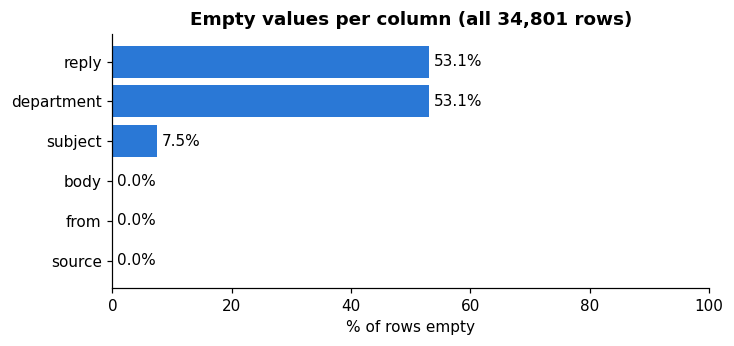

In [4]:
empty = (emails.drop(columns=["id", "spam"]) == "").mean().sort_values() * 100

fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.barh(empty.index, empty.values, color=BLUE)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in empty.values], padding=3)
ax.set_xlim(0, 100)
ax.set_xlabel("% of rows empty")
ax.set_title("Empty values per column (all 34,801 rows)")
plt.show()

**Conclusion.** `from` and `body` are never empty. `subject` is empty in 7.5% of
rows, `department` in 53% and `reply` in 53%. These are **not** errors to fill:
an empty subject is normal in real email, and an empty department means "this
source has no label". We don't fill any of them with a default value (filling the
department would invent labels, and `unclear` is a real class, not "missing").
The next chart shows *where* the gaps are.

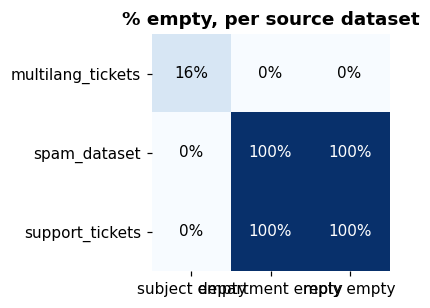

In [5]:
by_source = (emails[["subject", "department", "reply"]] == "").groupby(emails["source"]).mean() * 100

fig, ax = plt.subplots(figsize=(6, 2.8))
im = ax.imshow(by_source.values, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(by_source.shape[1]), [f"{c} empty" for c in by_source.columns])
ax.set_yticks(range(by_source.shape[0]), by_source.index)
for i in range(by_source.shape[0]):
    for j in range(by_source.shape[1]):
        v = by_source.iat[i, j]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", color="white" if v > 50 else "black")
ax.set_title("% empty, per source dataset")
ax.spines[:].set_visible(False)
plt.show()

**Conclusion.** The gaps are **structural, not random**: `department` and `reply`
are empty for 100% of the spam and support-ticket rows and for 0% of the IT
tickets, and empty subjects occur *only* in the IT tickets (16%). So "is this
field empty?" tells you which source a row came from. Decision: department
routing is trained and scored only on the 16,338 labelled rows; spam uses all
rows. Because empty subjects exist only in non-spam mail, "no subject" is a fake
"not spam" signal in this data (more in section 4).

In [6]:
exact_dups = emails.duplicated(["subject", "body"]).sum()
body_dups = emails["body"].duplicated(keep=False)
broken = emails["body"].str.contains("{", regex=False)

print(f"Exact duplicates (same subject + body): {exact_dups}  (6 were removed in cleaning)")
print(f"Rows sharing a body with another row:   {body_dups.sum()}  -> by source:")
print(emails.loc[body_dups, "source"].value_counts().to_string(), "\n")
print(f"Bodies with leftover template/code fragments ('{{'): {broken.sum()} "
      f"({broken.mean():.1%}) -> by source:")
print(emails.loc[broken, "source"].value_counts().to_string(), "\n")
print("Example:", emails.loc[broken, "body"].iloc[1][:230])

Exact duplicates (same subject + body): 0  (6 were removed in cleaning)
Rows sharing a body with another row:   121  -> by source:
source
support_tickets      119
multilang_tickets      2 

Bodies with leftover template/code fragments ('{'): 366 (1.1%) -> by source:
source
support_tickets    366 

Example: I'm having an issue with the Microsoft Office. Please assist. */

} else {

return results;

}

}

if (! product_purchased ) {

return results I've tried different settings and configurations on my Microsoft Office, but the issue 


**Conclusion (duplicates and wrong values).**
- **Duplicates:** no exact duplicates are left (6 were removed when building the
  dataset). 121 rows share a body with another row but have a *different*
  subject (119 of them are generated support tickets such as "I'm having an issue
  with the Amazon Echo..."). Decision: **keep** them, they are different emails
  with a common template sentence, like real customers writing similar things.
- **Wrong values:** 366 bodies (1.1%) still contain broken template or code
  fragments from the generator of the support-ticket dataset (`{product_p`,
  `<input type="submit"...>`, JSON pieces). The complete placeholders were filled
  in cleaning; these are cut-off ones. Decision: **keep and flag**. They are all
  in the unlabelled source, so they can't teach the router a wrong label, and real
  inbox mail also contains pasted junk. We will drop or repair them if the
  synthetic M3 mail replaces this source.

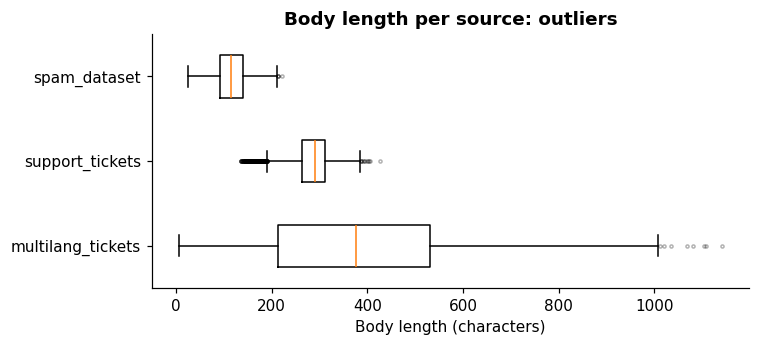

                     min    50%     max
source                                 
multilang_tickets    6.0  377.0  1141.0
spam_dataset        25.0  115.5   221.0
support_tickets    135.0  291.0   427.0


In [7]:
order = ["multilang_tickets", "support_tickets", "spam_dataset"]
fig, ax = plt.subplots(figsize=(7, 3))
ax.boxplot([df.loc[df["source"] == s, "body_length"] for s in order], vert=False,
           tick_labels=order, widths=0.5, flierprops={"markersize": 2, "alpha": 0.3})
ax.set_xlabel("Body length (characters)")
ax.set_title("Body length per source: outliers")
plt.show()
print(df.groupby("source")["body_length"].describe()[["min", "50%", "max"]])

**Conclusion (outliers).** Bodies range from 6 to 1,141 characters. The long
tail (up to 1,141) is in the IT tickets: long, detailed tickets, not errors. The
shortest bodies ("Assistance Required", "Facing some problems") are short but real
requests. Decision: **keep all lengths**; none are impossible values. Spam-dataset
bodies sit in a narrow band, which already hints that its text is generated.

## 3. Distributions

Which values occur and how often, especially in the two target columns: is the
data balanced?

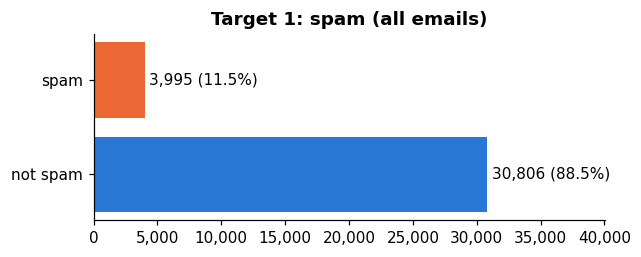

In [8]:
spam_counts = emails["spam"].map({0: "not spam", 1: "spam"}).value_counts()

fig, ax = plt.subplots(figsize=(6, 2.2))
bars = ax.barh(spam_counts.index, spam_counts.values, color=[BLUE, ORANGE])
ax.bar_label(bars, labels=[f"{v:,} ({v / len(emails):.1%})" for v in spam_counts.values], padding=3)
ax.set_xlim(0, spam_counts.max() * 1.3)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_title("Target 1: spam (all emails)")
plt.show()

**Conclusion.** The spam target has **both classes** (3,995 spam, 30,806 not spam),
but it is **imbalanced**: 11.5% spam. Always answering "not spam" is already 88.5%
accurate, so the spam filter has to be judged by precision/recall on the spam
class, not by accuracy alone.

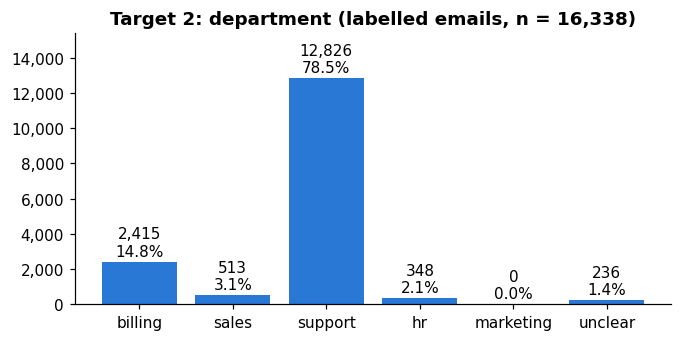

In [9]:
labelled = df[df["department"] != ""]
dept_counts = labelled["department"].value_counts().reindex(DEPARTMENTS, fill_value=0)

fig, ax = plt.subplots(figsize=(7, 3.2))
bars = ax.bar(dept_counts.index, dept_counts.values, color=BLUE)
ax.bar_label(bars, labels=[f"{v:,}\n{v / len(labelled):.1%}" for v in dept_counts.values], padding=2)
ax.set_ylim(0, dept_counts.max() * 1.2)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.set_title(f"Target 2: department (labelled emails, n = {len(labelled):,})")
plt.show()

**Conclusion.** The department target is **very imbalanced**: `support` is 78.5%
of the labelled emails, `billing` 14.8%, `sales` 3.1%, `hr` 2.1%, `unclear` 1.4%,
and `marketing` has **0 rows**. A model can look good by always answering
"support", so we report per-department scores and macro-F1. Marketing has to come
from synthetic mail (planned for M3), and with only 236 `unclear` and 348 `hr`
examples those classes will be the hardest.

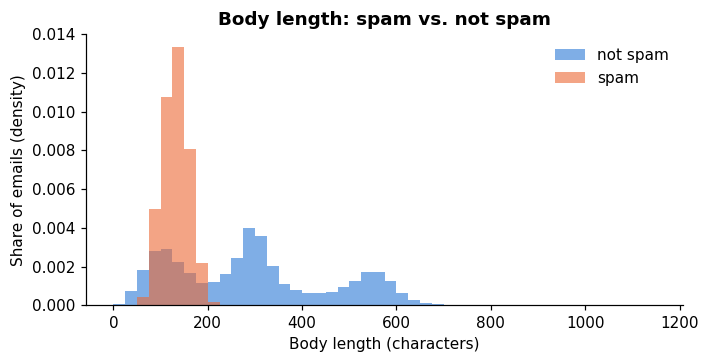

spam
not spam median    285.0
spam median        131.0
Name: body_length, dtype: float64


In [10]:
fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.linspace(0, 1150, 47)
for label, color, name in [(0, BLUE, "not spam"), (1, ORANGE, "spam")]:
    ax.hist(df.loc[df["spam"] == label, "body_length"], bins=bins, density=True,
            alpha=0.6, color=color, label=name)
ax.set_xlabel("Body length (characters)")
ax.set_ylabel("Share of emails (density)")
ax.set_title("Body length: spam vs. not spam")
ax.legend(frameon=False)
plt.show()
print(df.groupby("spam")["body_length"].median().rename({0: "not spam median", 1: "spam median"}))

**Conclusion.** Spam is **much shorter**: median body 131 characters vs. 285 for
real mail, and almost no spam is longer than ~200 characters. Length alone already
separates a big part of the classes, so there is signal for the spam target.
(Part of it is the source: the not-spam mail in the spam dataset is short too,
the long mail comes from the ticket datasets.)

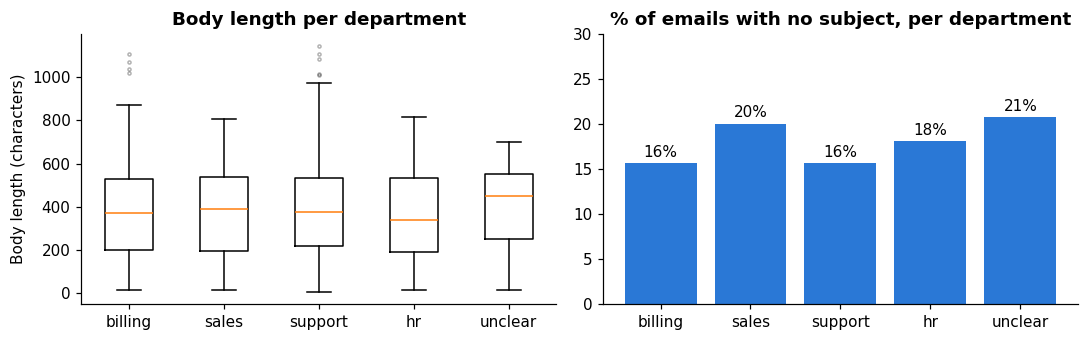

In [11]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.2))
present = [d for d in DEPARTMENTS if dept_counts[d] > 0]
a1.boxplot([labelled.loc[labelled["department"] == d, "body_length"] for d in present],
           tick_labels=present, flierprops={"markersize": 2, "alpha": 0.3})
a1.set_ylabel("Body length (characters)")
a1.set_title("Body length per department")

no_subj = (1 - labelled.groupby("department")["has_subject"].mean()).reindex(present) * 100
bars = a2.bar(no_subj.index, no_subj.values, color=BLUE)
a2.bar_label(bars, labels=[f"{v:.0f}%" for v in no_subj.values], padding=2)
a2.set_ylim(0, 30)
a2.set_title("% of emails with no subject, per department")
plt.tight_layout()
plt.show()

**Conclusion.** Inside the labelled mail, length and "has a subject" look **almost
the same for every department** (medians 338-452 characters; 16-21% have no subject).
So these simple features won't route an email: the department signal has to come
from **what the email says** (section 4 checks words). And since ~1 in 6 business
emails has no subject, the router must read the body, not only the subject line.

## 4. Correlation and leakage

Which columns move together, and how strongly is each one related to the target?
A very high correlation with the target (around 0.9+) is a **leakage suspect**:
the column may already contain the answer.

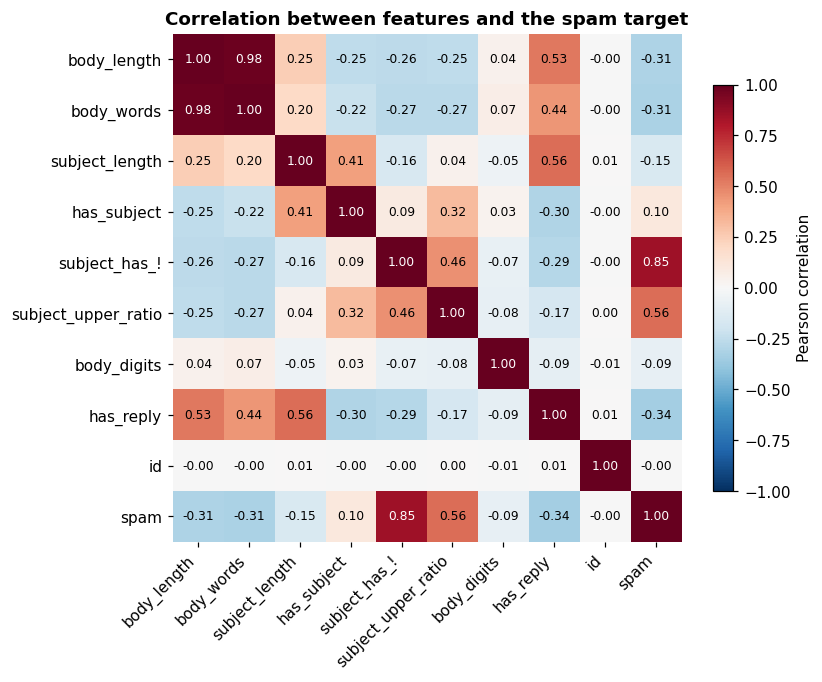

In [12]:
corr = pd.concat([feat, emails["spam"]], axis=1).corr()

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(v) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8, label="Pearson correlation")
ax.set_title("Correlation between features and the spam target")
ax.spines[:].set_visible(False)
plt.show()

**Conclusion.** `body_length` and `body_words` move together almost perfectly
(0.98): they measure the same thing, so we keep only one. `has_reply` goes with
longer bodies and subjects (0.53-0.56) because only the long IT tickets have
replies. `id` correlates with nothing (0.00), which confirms the shuffle worked
and row order leaks nothing. Against `spam`, one feature stands out: see the next chart.

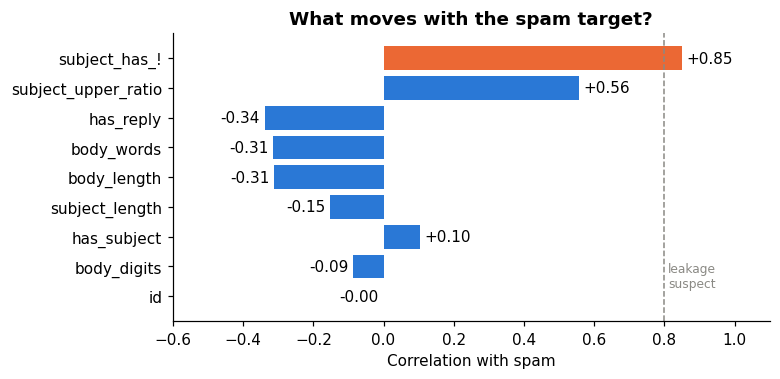

subject_has_!  no '!'  '!' in subject
spam                                 
not spam        1.000           0.000
spam            0.256           0.744


In [13]:
to_spam = corr["spam"].drop("spam").sort_values(key=abs)

fig, ax = plt.subplots(figsize=(7, 3.4))
colors = [ORANGE if abs(v) >= 0.8 else BLUE for v in to_spam.values]
bars = ax.barh(to_spam.index, to_spam.values, color=colors)
ax.bar_label(bars, labels=[f"{v:+.2f}" for v in to_spam.values], padding=3)
ax.axvline(0.8, color=GREY, ls="--", lw=1)
ax.text(0.81, 0.3, "leakage\nsuspect", color=GREY, fontsize=8)
ax.set_xlim(-0.6, 1.1)
ax.set_xlabel("Correlation with spam")
ax.set_title("What moves with the spam target?")
plt.show()
print(pd.crosstab(df["spam"], df["subject_has_!"], normalize="index").round(3)
      .rename(index={0: "not spam", 1: "spam"}, columns={0: "no '!'", 1: "'!' in subject"}))

**Conclusion: a leak.** `subject_has_!` has a correlation of **0.85** with spam:
74% of spam subjects contain "!" and **0%** of real mail does. That is not a rule
of real email (real people write "Thanks!"), it's an artifact of the synthetic
spam dataset. A model would learn "! = spam" and fail on real mail, so we
**won't build features or prompts around it**, and spam accuracy measured on this
data is optimistic. `subject_upper_ratio` (0.56) is the same effect in a weaker
form (shouted, capitalised spam subjects). Body length (-0.31) is a moderate, more
believable signal.

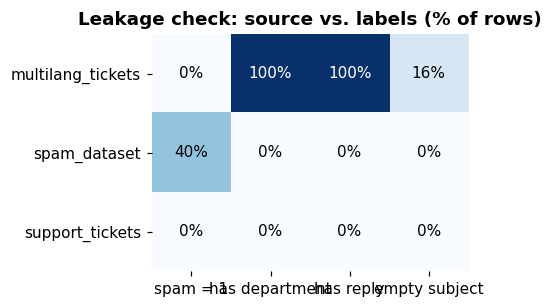

In [14]:
labels = pd.DataFrame({
    "spam = 1": emails["spam"] == 1,
    "has department": emails["department"] != "",
    "has reply": emails["reply"] != "",
    "empty subject": emails["subject"] == "",
}).groupby(emails["source"]).mean() * 100

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.imshow(labels.values, cmap="Blues", vmin=0, vmax=100)
ax.set_xticks(range(labels.shape[1]), labels.columns)
ax.set_yticks(range(labels.shape[0]), labels.index)
for i in range(labels.shape[0]):
    for j in range(labels.shape[1]):
        v = labels.iat[i, j]
        ax.text(j, i, f"{v:.0f}%", ha="center", va="center", color="white" if v > 50 else "black")
ax.set_title("Leakage check: source vs. labels (% of rows)")
ax.spines[:].set_visible(False)
plt.show()

**Conclusion: `source` and `reply` leak the labels.** Spam exists only in the spam
dataset, departments and replies exist only in the IT tickets. So `source` (and
"has a reply") tells you whether a row can be spam and whether it has a
department. Decision: **`source`, `reply`, `id` and `from` are never model
inputs**; the model sees only `subject` and `body`, exactly like the real pipeline,
which only gets the email. (We already removed the other leaks during cleaning:
the original sender domains and the row order revealed the source.)

In [15]:
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table, correction=False)[0]
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))

def correlation_ratio(cats, values):
    # eta: how much of a numeric column's variance is explained by the category
    means = values.groupby(cats).transform("mean")
    return np.sqrt(((means - values.mean()) ** 2).sum() / ((values - values.mean()) ** 2).sum())

dept = labelled["department"]
pd.DataFrame({
    "association with department": {
        "body_length (eta)": correlation_ratio(dept, labelled["body_length"]),
        "subject_length (eta)": correlation_ratio(dept, labelled["subject_length"]),
        "body_digits (eta)": correlation_ratio(dept, labelled["body_digits"]),
        "has_subject (Cramer's V)": cramers_v(dept, labelled["has_subject"]),
        "from (Cramer's V)": cramers_v(dept, labelled["from"]),
    }
}).round(3)

,association with department
body_length (eta),0.027
subject_length (eta),0.005
body_digits (eta),0.024
has_subject (Cramer's V),0.028
from (Cramer's V),0.252


**Conclusion.** For `department` the surface features carry **almost no signal**:
length, digits and "has a subject" all have associations below 0.1. The random
sender `from` has a Cramer's V of 0.25, but that's what 1,000 random categories
give by chance on 16k rows (many tiny cells), not real signal, and it's not an input
anyway. No feature is suspiciously strong, so there's no leak for the department
target. The signal must be in the words, which the next chart tests.

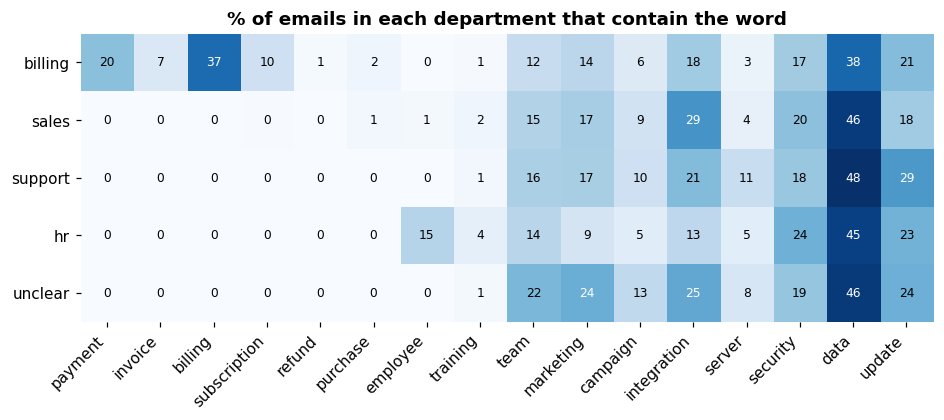

In [16]:
WORDS = ["payment", "invoice", "billing", "subscription", "refund", "purchase",
         "employee", "training", "team", "marketing", "campaign", "integration",
         "server", "security", "data", "update"]
text = (labelled["subject"] + " " + labelled["body"]).str.lower()
share = pd.DataFrame({w: text.str.contains(rf"\b{w}", regex=True) for w in WORDS})
share = share.groupby(labelled["department"]).mean().reindex(present) * 100

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.imshow(share.values, cmap="Blues", aspect="auto", vmin=0, vmax=share.values.max())
ax.set_xticks(range(len(WORDS)), WORDS, rotation=45, ha="right")
ax.set_yticks(range(len(present)), present)
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        v = share.iat[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8,
                color="white" if v > share.values.max() / 2 else "black")
ax.set_title("% of emails in each department that contain the word")
ax.spines[:].set_visible(False)
plt.show()

**Conclusion: there is signal in the text, and one warning.** Some words point to
one department: "billing" is in 37% of `billing` emails, "payment" in 20%,
"subscription" in 10%, and "employee" in 15% of `hr` emails. Other words ("data",
"update", "security", "team") appear everywhere and don't help. This is the signal
the M3 model (an LLM reading the email) has to use.

**Warning (possible rule-made labels):** "billing", "payment", "invoice" and
"subscription" appear in **exactly 0%** of the ~13,900 non-billing emails. Real mail
is never that clean (a support ticket mentions a payment now and then). The
dataset's text was probably generated *from* the label, so a model can partly learn
the generator's word choice, and billing routing on this data will look easier than
on real mail. `sales` and `unclear` have no such marker words ("integration" and
"marketing" are spread over all departments), so they will be the hard classes; spot
checks also found integration questions labelled `billing` (noisy labels).

## 5. Baselines

The simplest possible prediction: always answer the most common class.

In [17]:
def majority_baseline(y):
    majority = y.mode()[0]
    acc = (y == majority).mean()
    # macro-F1: F1 is 0 for every class except the majority one
    f1_major = 2 * acc / (1 + acc)
    return majority, acc, f1_major / y.nunique()

rows = []
for name, y in [("department (labelled rows)", labelled["department"]),
                ("spam (all rows)", emails["spam"].map({0: "not spam", 1: "spam"}))]:
    majority, acc, macro_f1 = majority_baseline(y)
    rows.append({"target": name, "rows": len(y), "always predict": majority,
                 "accuracy": f"{acc:.1%}", "macro-F1": round(macro_f1, 2)})
pd.DataFrame(rows).set_index("target")

,rows,always predict,accuracy,macro-F1
target,,,,
department (labelled rows),16338,support,78.5%,0.18
spam (all rows),34801,not spam,88.5%,0.47


**Conclusion.** The M3 model must beat **78.5% accuracy** on department routing
(always `support`) and **88.5% accuracy** on spam (always "not spam"). Because
both baselines get 0 on every minority class, their macro-F1 is low (0.18 and
0.47): that's the number that shows whether a model actually routes billing, sales
and hr mail instead of just copying the majority.

## Summary

1. **Column types:** text data; targets `spam` (binary) and `department`
   (categorical). `id`, `from`, `source`, `reply` are not model inputs.
2. **Quality:** gaps are structural (per source), not random; no exact duplicates;
   366 bodies (1.1%, unlabelled source) have broken generator fragments: kept and flagged.
3. **Distributions:** both targets are imbalanced (78.5% `support`, 11.5% spam), and
   `marketing` has no examples yet.
4. **Correlation:** "!" in the subject (0.85 with spam) and `source`/`reply` are
   leaks from how the datasets were made. The department signal is in the words,
   but billing words appear in 0% of other mail, a sign the text was generated from the label.
5. **Insight + baseline:** 78.5% of labelled business mail is `support`; the model must
   beat 78.5% (department) and 88.5% (spam), and is judged per department / macro-F1.